# Module 2 — Day 2: Data Augmentation

In this notebook, I will add simple data augmentation to the CIFAR-10 training images and compare it with the original training setup.

The idea is to show the model slightly different versions of training images, so it doesn't rely too much on exact pixel positions. I will keep validation and test images unchanged so the evaluation stays fair.

1. Imports and setup

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

BATCH_SIZE = 128
EPOCHS = 8

Device: cpu


2. Prepare the datasets

I use random horizontal flips and random crops only for the training set. Validation and test sets use normalization without random transformations.

In [2]:
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# Separate dataset objects let us apply different transforms to each split.
train_full = datasets.CIFAR10(root="data", train=True, download=True, transform=train_transform)
eval_full = datasets.CIFAR10(root="data", train=True, download=True, transform=eval_transform)
test_data = datasets.CIFAR10(root="data", train=False, download=True, transform=eval_transform)

train_indices, val_indices = random_split(
    range(len(train_full)), [45000, 5000],
    generator=torch.Generator().manual_seed(SEED)
)
train_data = torch.utils.data.Subset(train_full, train_indices.indices)
val_data = torch.utils.data.Subset(eval_full, val_indices.indices)

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())

class_names = train_full.classes
print(f"Train: {len(train_data)} | Validation: {len(val_data)} | Test: {len(test_data)}")

100%|██████████| 170M/170M [28:26<00:00, 99.9kB/s]


Train: 45000 | Validation: 5000 | Test: 10000


3. Look at the augmented images

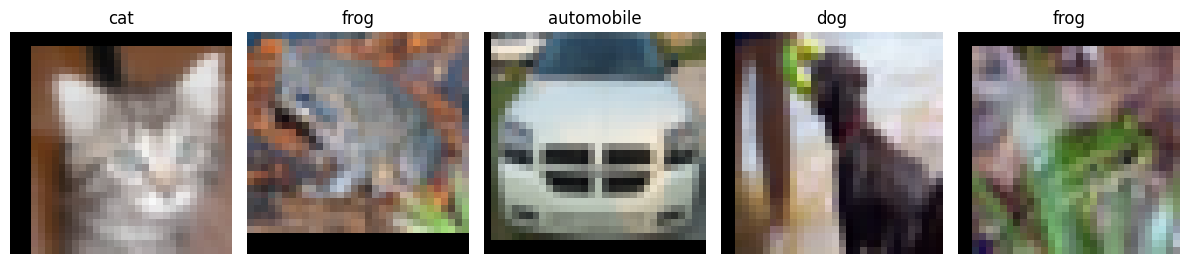

In [3]:
images, labels = next(iter(train_loader))
mean = torch.tensor(MEAN).view(3, 1, 1)
std = torch.tensor(STD).view(3, 1, 1)

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i, ax in enumerate(axes):
    image = (images[i].cpu() * std + mean).clamp(0, 1)
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")
plt.tight_layout()
plt.show()

4. Define the CNN

This is a small CNN trained from scratch, similar in spirit to the one from Module 1. No pretrained model is used.

In [4]:
class CIFAR10CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = CIFAR10CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
print(model)

CIFAR10CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


5. Training and evaluation functions

In [5]:
def run_epoch(loader, training=False):
    model.train() if training else model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            if training:
                optimizer.zero_grad()

            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total

6. Train the model

In [6]:
history = {
    "epoch": [],
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss, val_acc = run_epoch(val_loader, training=False)

    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss {train_loss:.4f} | train acc {train_acc:.2%} | "
        f"val loss {val_loss:.4f} | val acc {val_acc:.2%}"
    )

Epoch 01/8 | train loss 1.6492 | train acc 39.23% | val loss 1.3606 | val acc 51.52%
Epoch 02/8 | train loss 1.3032 | train acc 52.76% | val loss 1.1261 | val acc 59.46%
Epoch 03/8 | train loss 1.1182 | train acc 60.17% | val loss 0.9687 | val acc 65.80%
Epoch 04/8 | train loss 0.9972 | train acc 64.98% | val loss 0.9303 | val acc 66.60%
Epoch 05/8 | train loss 0.9057 | train acc 68.11% | val loss 0.7837 | val acc 72.08%
Epoch 06/8 | train loss 0.8419 | train acc 70.24% | val loss 0.7580 | val acc 73.10%
Epoch 07/8 | train loss 0.7931 | train acc 72.22% | val loss 0.7721 | val acc 73.14%
Epoch 08/8 | train loss 0.7530 | train acc 73.43% | val loss 0.7443 | val acc 73.68%


7. Plot the results

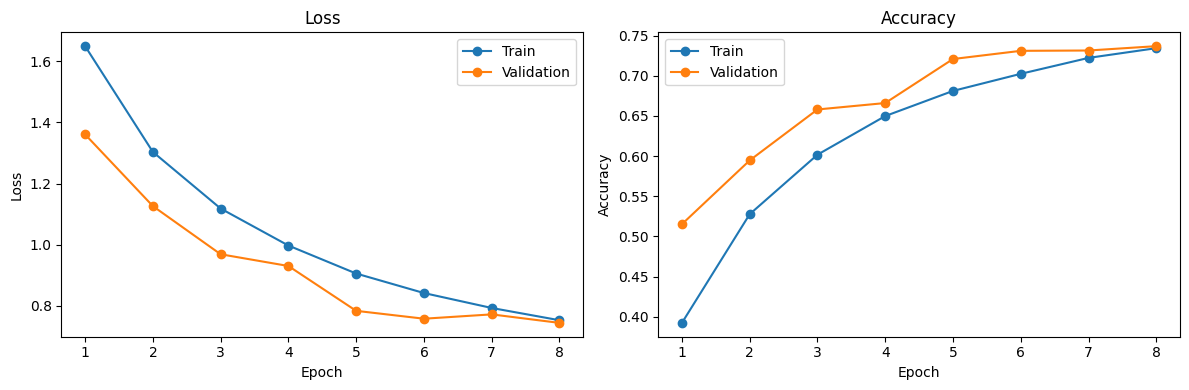

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["epoch"], history["train_loss"], marker="o", label="Train")
axes[0].plot(history["epoch"], history["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history["epoch"], history["train_accuracy"], marker="o", label="Train")
axes[1].plot(history["epoch"], history["val_accuracy"], marker="o", label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

8. Evaluate on the test set

The test set is only used after training. It has no random augmentation.

In [8]:
test_loss, test_acc = run_epoch(test_loader, training=False)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.2%}")

Test loss: 0.7512
Test accuracy: 74.28%


9. What I noticed

After running the notebook, write a few sentences in your own words:

- Did training accuracy stay lower than it did in Module 1?
- Did the gap between training and validation accuracy change?
- Did test accuracy improve, stay similar, or decrease?

Data augmentation does not guarantee a higher score in every run. The point is to compare how the model behaves when training images are varied.